<a href="https://colab.research.google.com/github/Manoj1823/DV-LAB/blob/main/Program1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Download latest dataset
path = kagglehub.dataset_download(
    "camnugent/california-housing-prices"
)

print("Path to dataset files:", path)

# Find CSV file
csv_files = [
    f for f in os.listdir(path)
    if f.endswith(".csv")
]

print("Available CSV files:", csv_files)

# Load dataset
df = pd.read_csv(os.path.join(path, csv_files[0]))

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Path to dataset files: /kaggle/input/california-housing-prices
Available CSV files: ['housing.csv']
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            3

In [ ]:
# Continuous variables
continuous_cols = [
    "longitude", "latitude", "housing_median_age",
    "total_rooms", "total_bedrooms",
    "population", "households",
    "median_income", "median_house_value"
]

# Discrete variables
discrete_cols = [
    "housing_median_age", "total_rooms",
    "total_bedrooms", "population", "households"
]

# Nominal variable
nominal_cols = ["ocean_proximity"]

print("Continuous variables:", continuous_cols)
print("Discrete variables:", discrete_cols)
print("Nominal variables:", nominal_cols)

Continuous variables: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
Discrete variables: ['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households']
Nominal variables: ['ocean_proximity']


In [ ]:
# Create an ordinal feature from median income
df["Income_Level"] = pd.cut(
    df["median_income"],
    bins=[-np.inf, 2, 4, 6, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

print(df[["median_income", "Income_Level"]].head())

   median_income Income_Level
0         8.3252    Very High
1         8.3014    Very High
2         7.2574    Very High
3         5.6431         High
4         3.8462       Medium


In [ ]:
# Check missing values
print("Missing values before treatment:")
print(df.isnull().sum())

# Numerical columns
num_cols = df.select_dtypes(include=np.number).columns

# Categorical columns
cat_cols = df.select_dtypes(
    include=["object", "category"]
).columns

# Fill numerical missing values with median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after treatment:")
print(df.isnull().sum().sum())

Missing values before treatment:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
Income_Level            0
dtype: int64

Missing values after treatment:
0


In [ ]:
print("Duplicates before:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


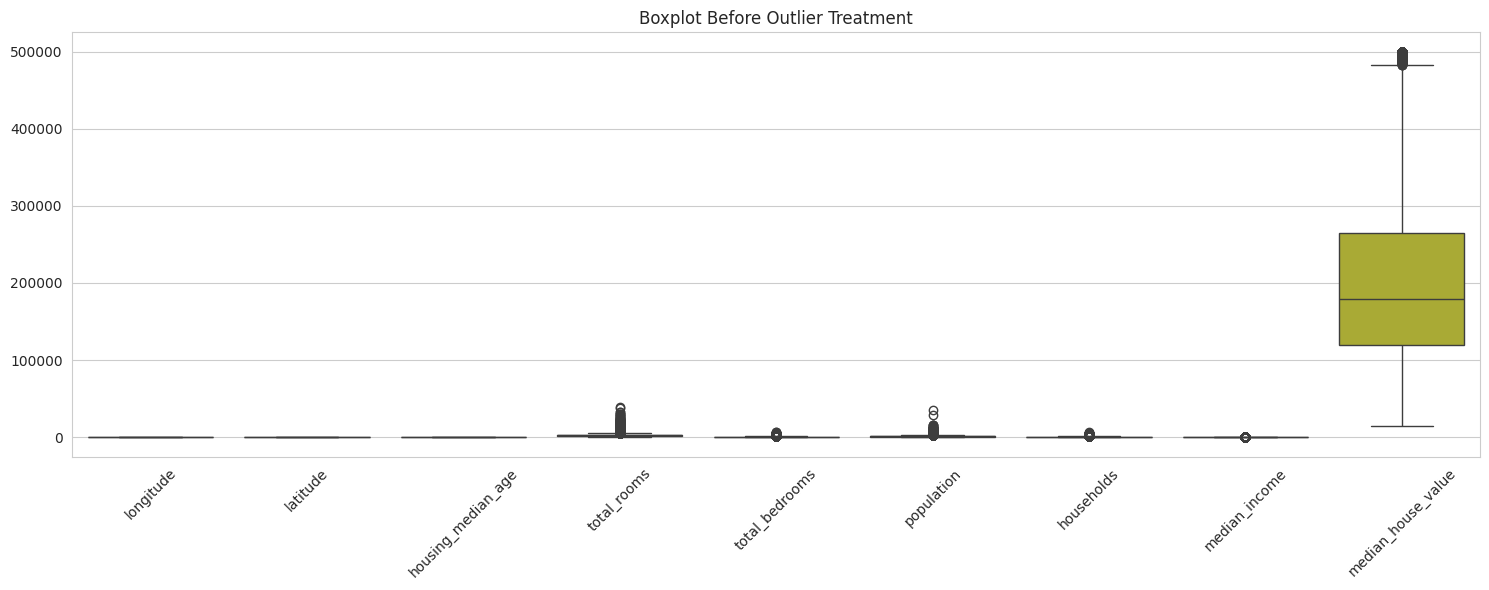

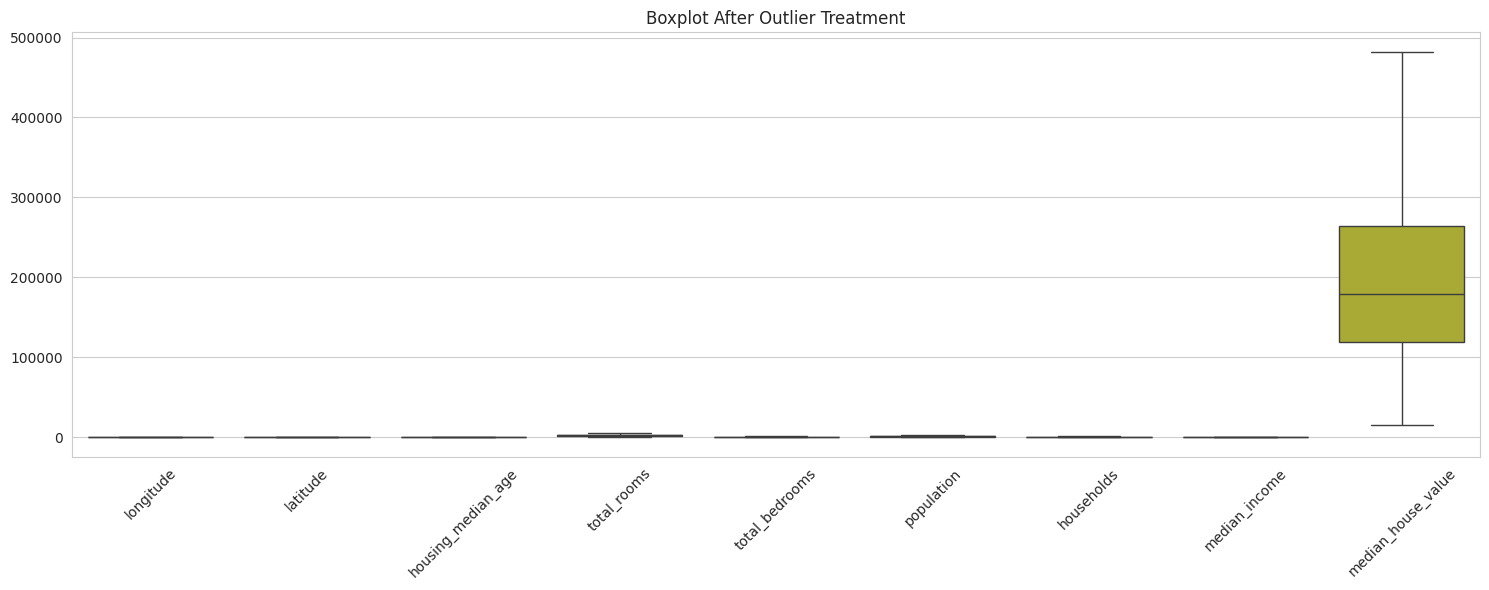

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns

# Boxplot before outlier treatment
plt.figure(figsize=(15, 6))

sns.boxplot(data=df[num_cols])

plt.title("Boxplot Before Outlier Treatment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# IQR outlier treatment
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

# Boxplot after treatment
plt.figure(figsize=(15, 6))

sns.boxplot(data=df[num_cols])

plt.title("Boxplot After Outlier Treatment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Ordinal encoding
income_mapping = {
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Very High": 4
}

df["Income_Level"] = df["Income_Level"].map(
    income_mapping
).astype(int)

# Nominal encoding
df = pd.get_dummies(
    df,
    columns=["ocean_proximity"],
    dtype=int
)

print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0      880.000           129.0   
1    -122.22     37.86                21.0     5698.375          1106.0   
2    -122.24     37.85                52.0     1467.000           190.0   
3    -122.25     37.85                52.0     1274.000           235.0   
4    -122.25     37.85                52.0     1627.000           280.0   

   population  households  median_income  median_house_value  Income_Level  \
0       322.0       126.0       8.013025            452600.0             4   
1      2401.0      1092.5       8.013025            358500.0             4   
2       496.0       177.0       7.257400            352100.0             4   
3       558.0       219.0       5.643100            341300.0             3   
4       565.0       259.0       3.846200            342200.0             2   

   ocean_proximity_<1H OCEAN  ocean_proximity_INLAND  ocean_proximity_ISLAND  \


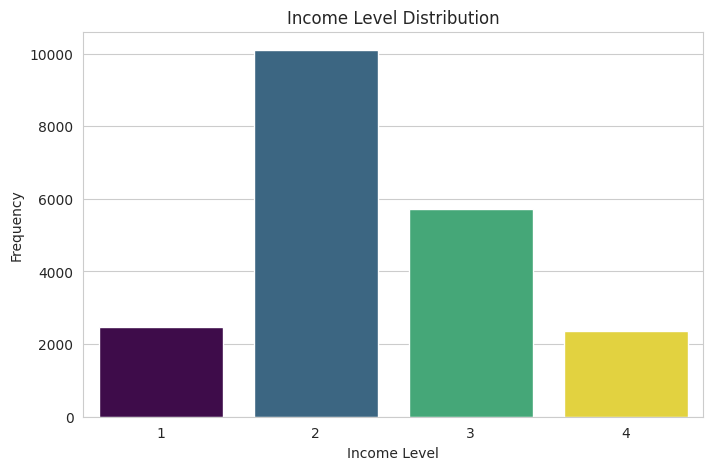

In [ ]:
# Bar plot for income level
plt.figure(figsize=(8, 5))

sns.countplot(
    x="Income_Level",
    data=df,
    hue="Income_Level",
    palette="viridis",
    legend=False
)

plt.title("Income Level Distribution")
plt.xlabel("Income Level")
plt.ylabel("Frequency")
plt.show()

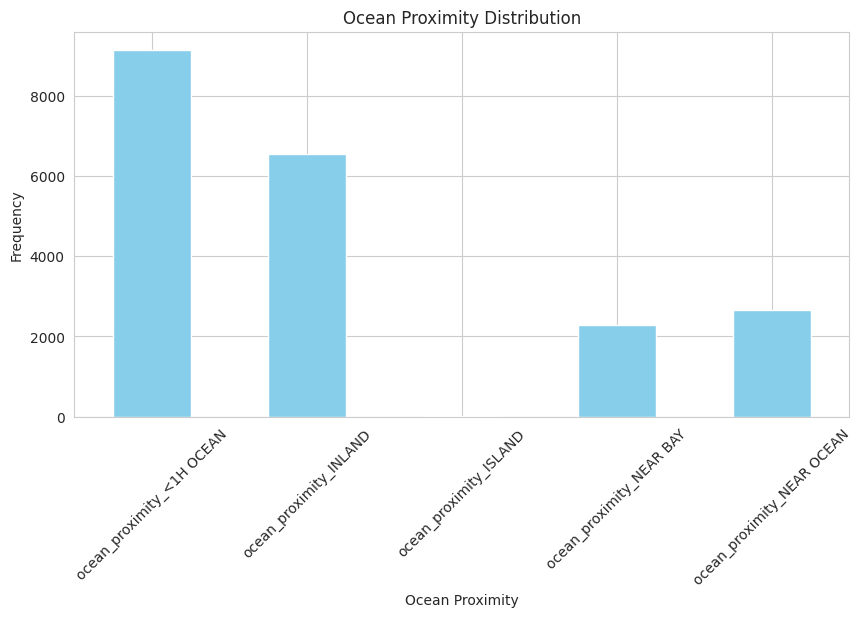

In [ ]:
# Bar plot for ocean proximity
ocean_cols = [
    col for col in df.columns
    if col.startswith("ocean_proximity_")
]

df[ocean_cols].sum().plot(
    kind="bar",
    color="skyblue"
)

plt.title("Ocean Proximity Distribution")
plt.xlabel("Ocean Proximity")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

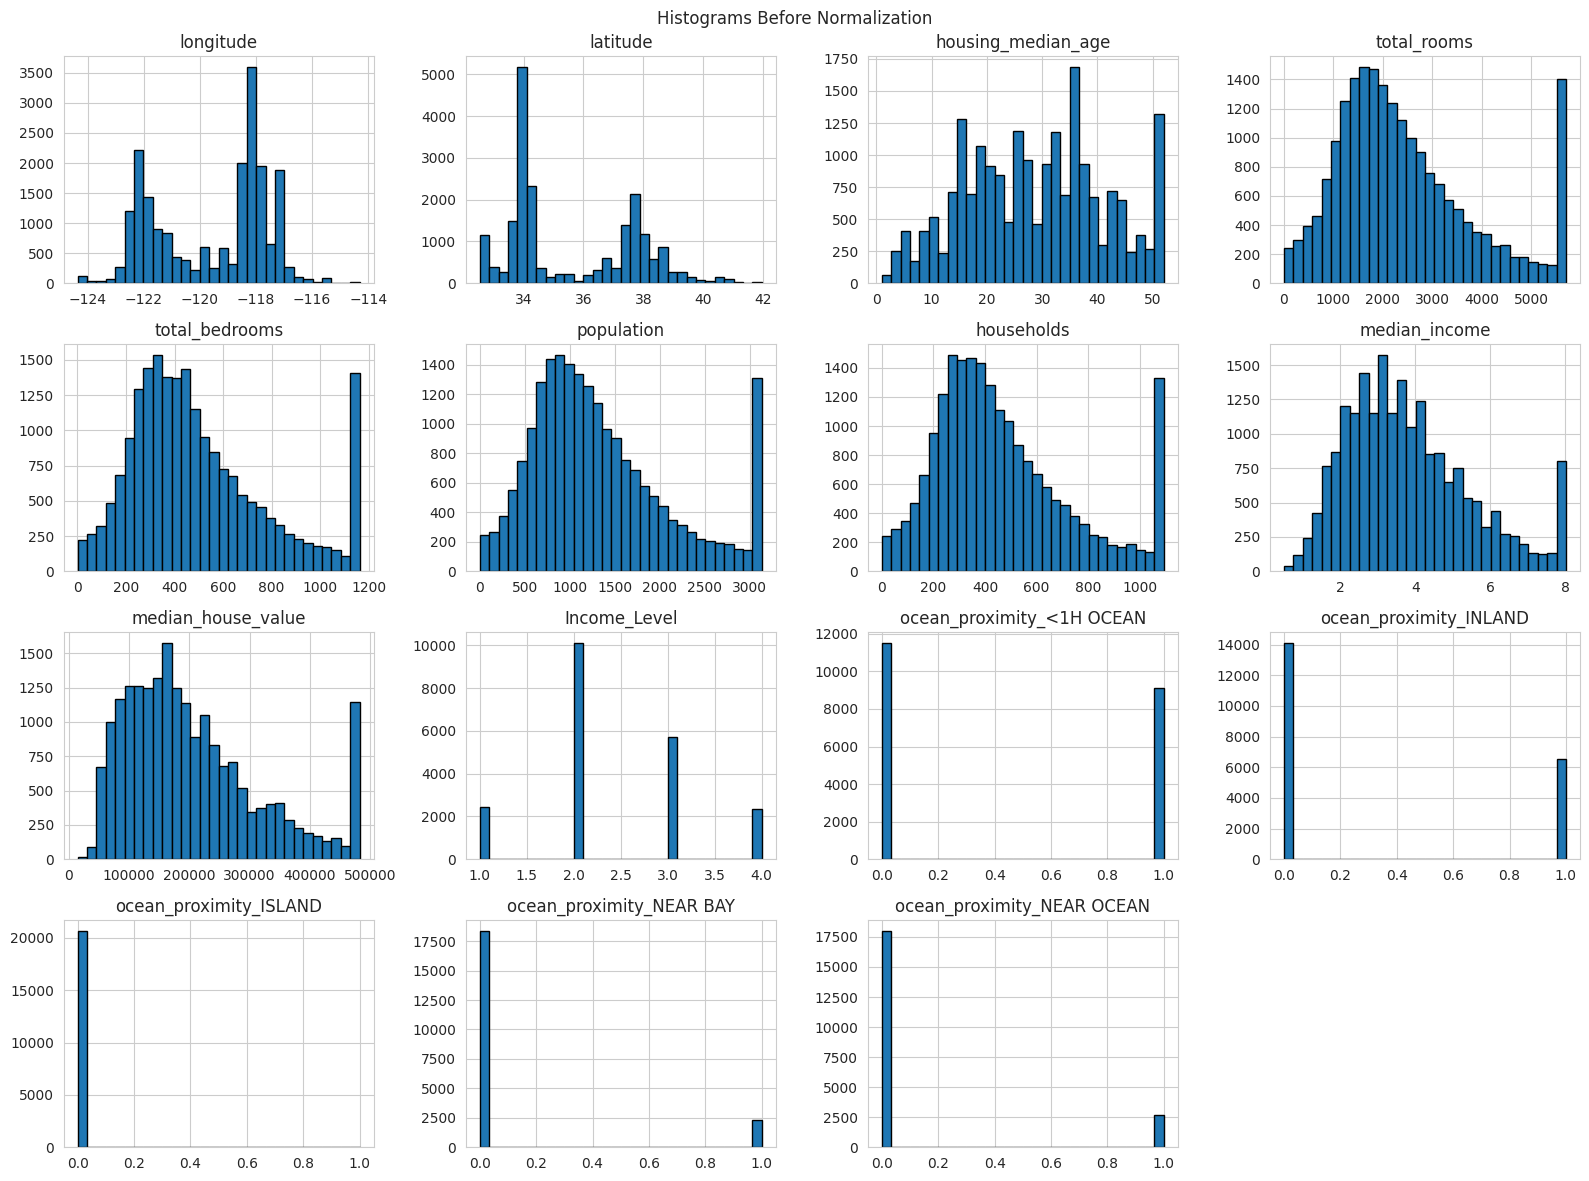

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Histograms Before Normalization")
plt.tight_layout()
plt.show()

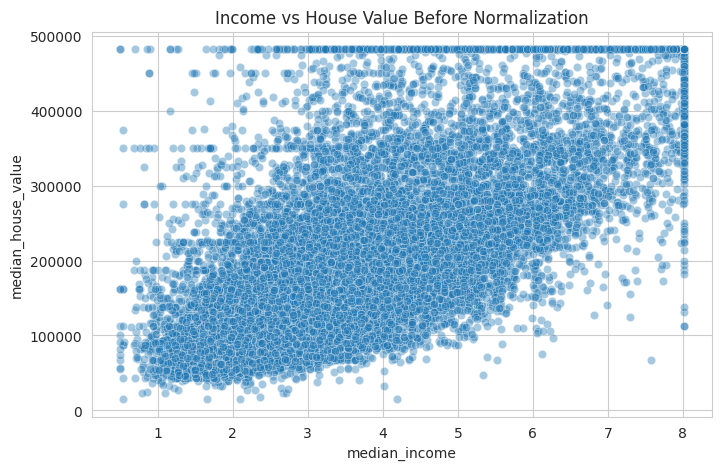

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.4
)

plt.title("Income vs House Value Before Normalization")
plt.show()

In [ ]:
df_minmax = df.copy()

scaler_minmax = MinMaxScaler()

df_minmax[num_cols] = scaler_minmax.fit_transform(
    df[num_cols]
)

print(df_minmax.head())

print("Minimum:", df_minmax[num_cols].min().min())
print("Maximum:", df_minmax[num_cols].max().max())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0   0.211155  0.567481            0.784314     0.154133        0.110190   
1   0.212151  0.565356            0.392157     1.000000        0.951254   
2   0.210159  0.564293            1.000000     0.257181        0.162703   
3   0.209163  0.564293            1.000000     0.223300        0.201442   
4   0.209163  0.564293            1.000000     0.285269        0.240181   

   population  households  median_income  median_house_value  Income_Level  \
0    0.101950    0.114521       1.000000            0.936218      1.000000   
1    0.766379    1.000000       1.000000            0.734897      1.000000   
2    0.157558    0.161246       0.899426            0.721205      1.000000   
3    0.177373    0.199725       0.684562            0.698099      0.666667   
4    0.179610    0.236372       0.445394            0.700025      0.333333   

   ocean_proximity_<1H OCEAN  ocean_proximity_INLAND  ocean_proximity_ISLAND  \


In [ ]:
df_standard = df.copy()

scaler_standard = StandardScaler()

df_standard[num_cols] = scaler_standard.fit_transform(
    df[num_cols]
)

print(df_standard.head())

print("Mean:")
print(df_standard[num_cols].mean().round(3))

print("Standard deviation:")
print(df_standard[num_cols].std().round(3))

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0  -1.327835  1.052548            0.982143    -1.117285       -1.309916   
1  -1.322844  1.043185           -0.607019     2.329936        2.128690   
2  -1.332827  1.038503            1.856182    -0.697327       -1.095223   
3  -1.337818  1.038503            1.856182    -0.835405       -0.936843   
4  -1.337818  1.038503            1.856182    -0.582857       -0.778463   

   population  households  median_income  median_house_value  Income_Level  \
0   -1.325821   -1.291972       2.541006            2.178330      1.921848   
1    1.389936    2.348314       2.541006            1.347165      1.921848   
2   -1.098528   -1.099883       2.085156            1.290635      1.921848   
3   -1.017539   -0.941691       1.111288            1.195241      0.730219   
4   -1.008395   -0.791033       0.027262            1.203191     -0.461410   

   ocean_proximity_<1H OCEAN  ocean_proximity_INLAND  ocean_proximity_ISLAND  \


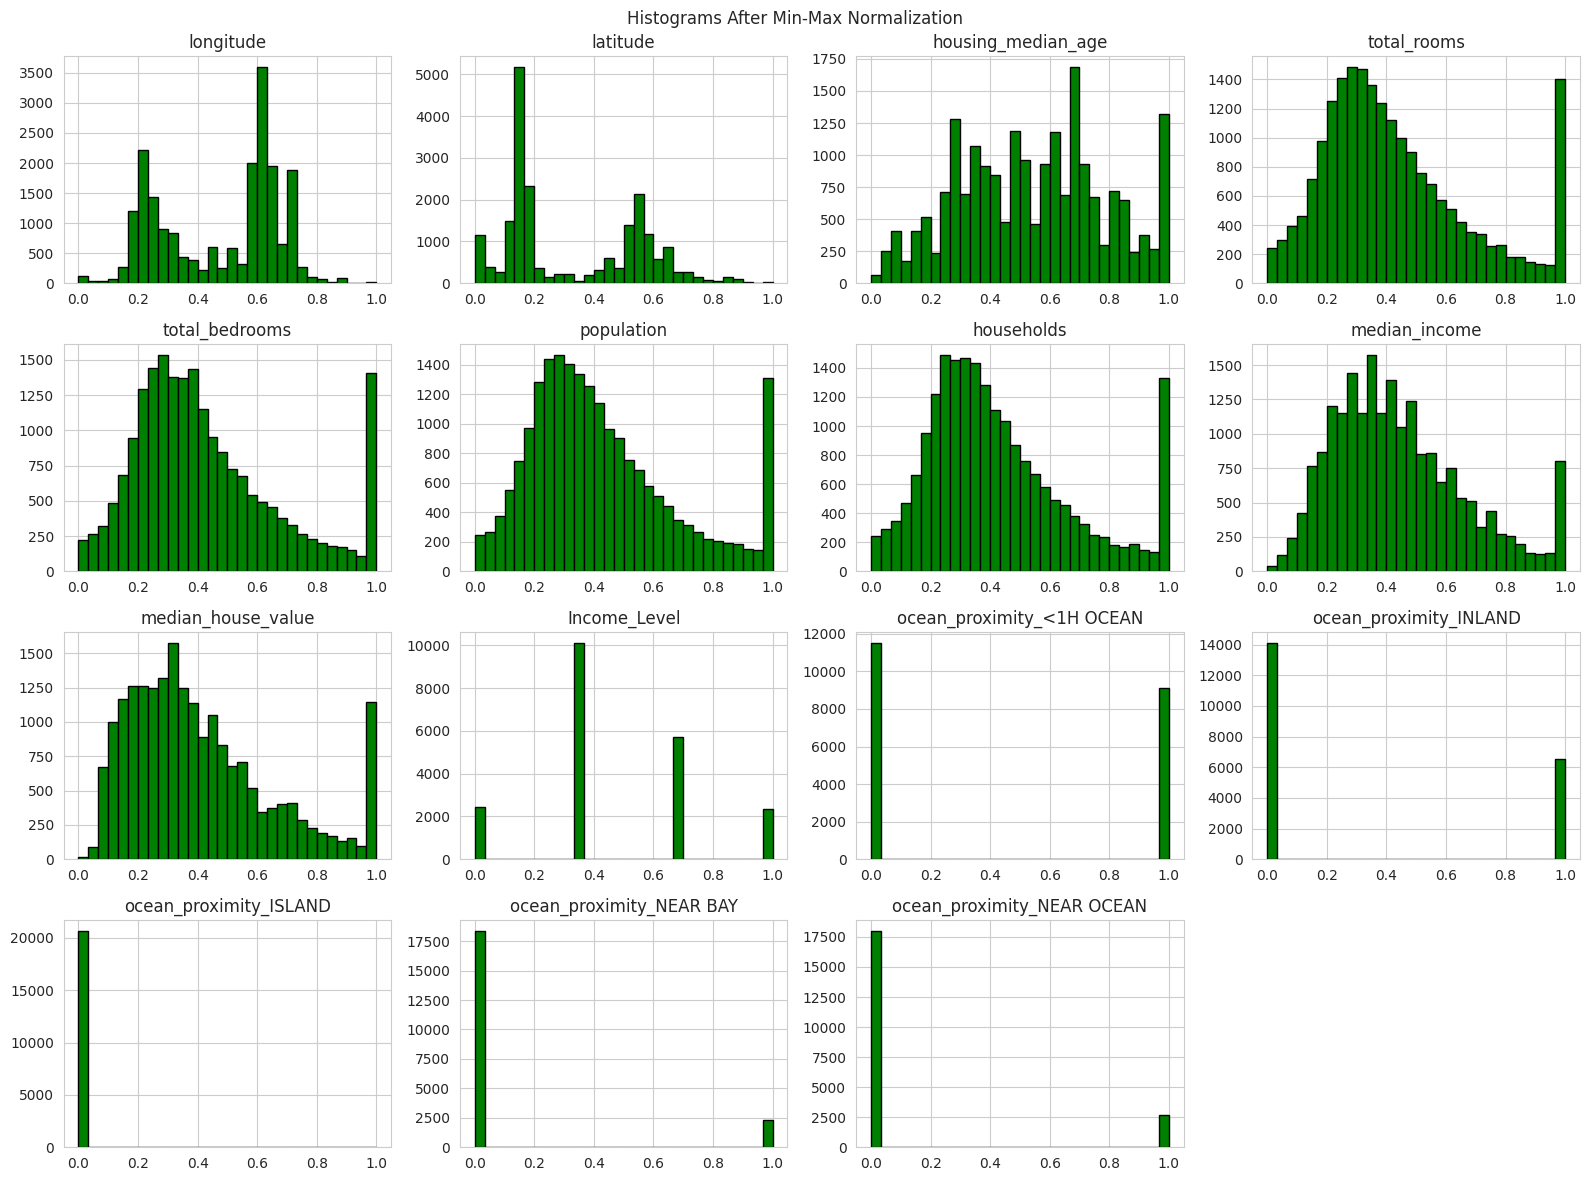

In [ ]:
df_minmax[num_cols].hist(
    figsize=(16, 12),
    bins=30,
    color="green",
    edgecolor="black"
)

plt.suptitle("Histograms After Min-Max Normalization")
plt.tight_layout()
plt.show()

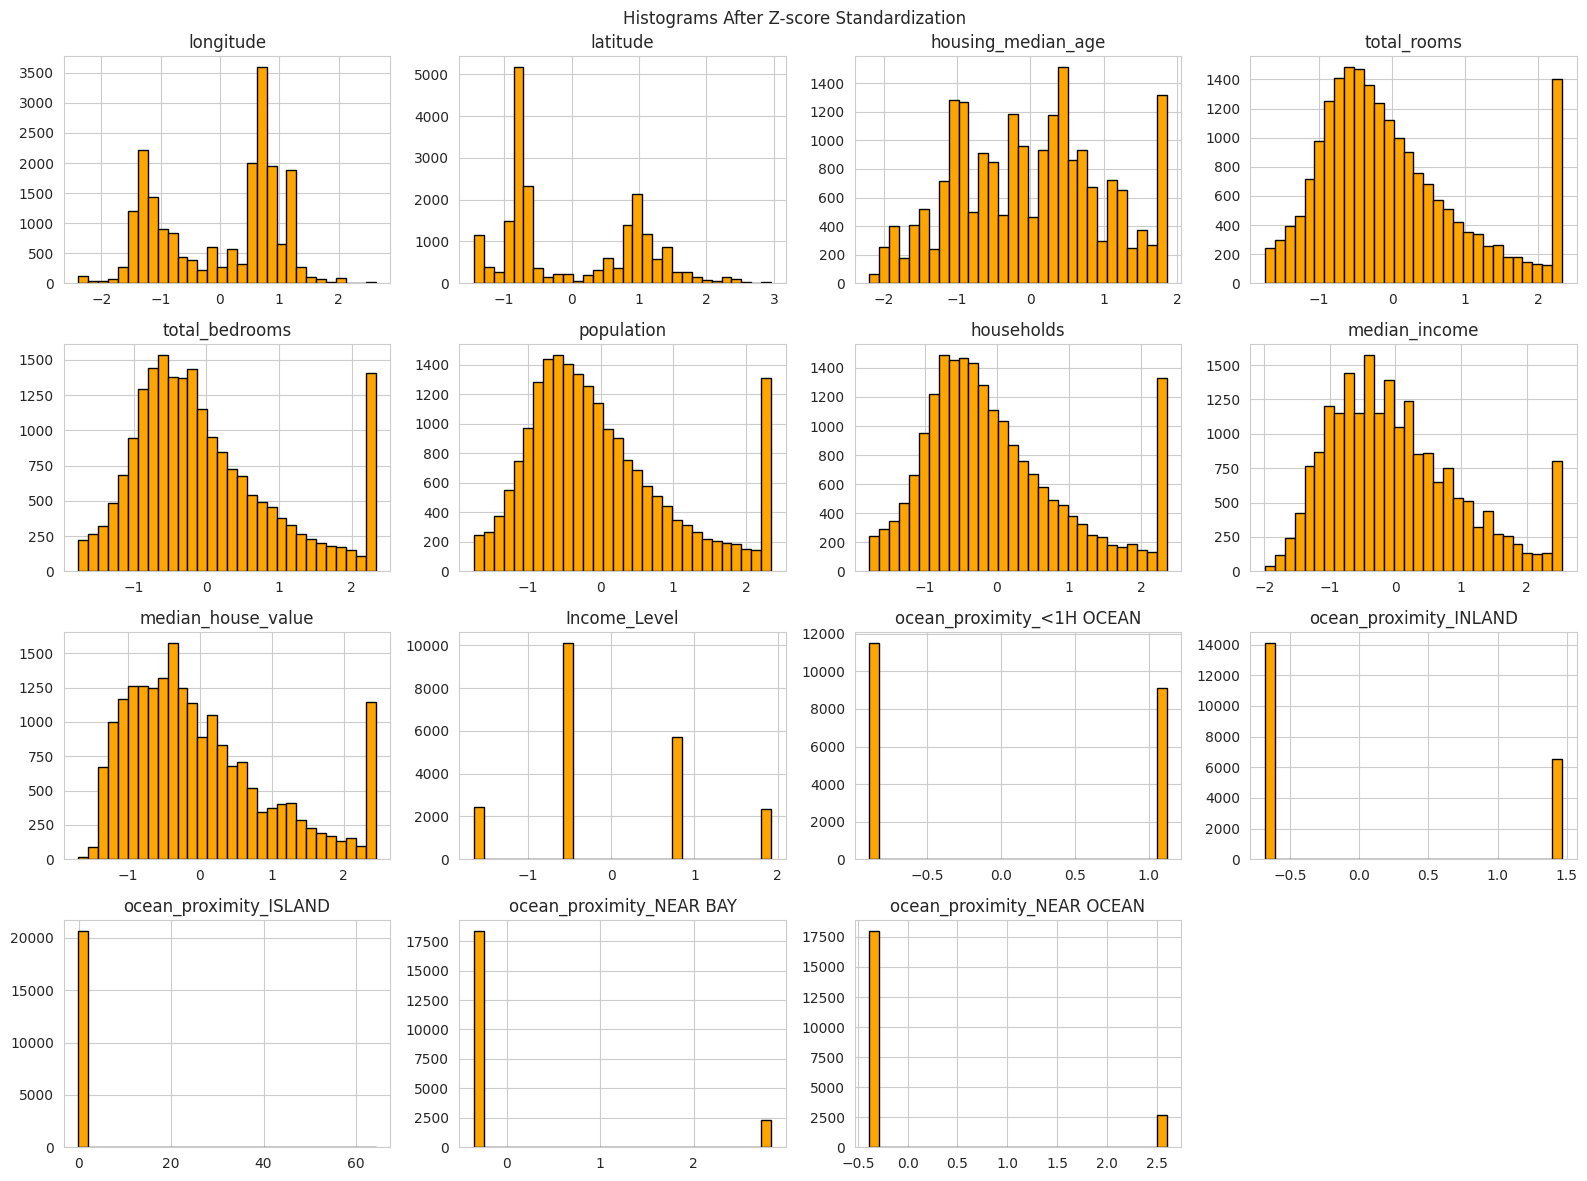

In [ ]:
df_standard[num_cols].hist(
    figsize=(16, 12),
    bins=30,
    color="orange",
    edgecolor="black"
)

plt.suptitle("Histograms After Z-score Standardization")
plt.tight_layout()
plt.show()

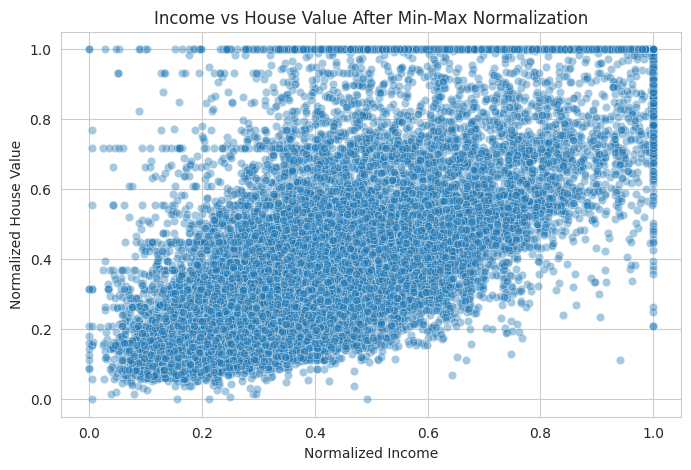

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_minmax,
    x="median_income",
    y="median_house_value",
    alpha=0.4
)

plt.title("Income vs House Value After Min-Max Normalization")
plt.xlabel("Normalized Income")
plt.ylabel("Normalized House Value")
plt.show()

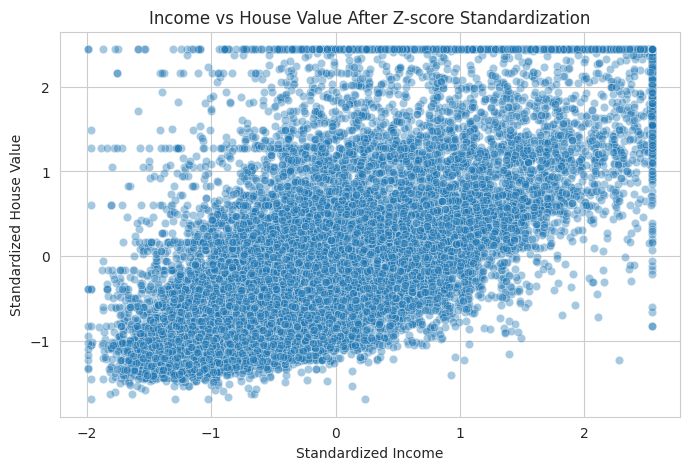

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_standard,
    x="median_income",
    y="median_house_value",
    alpha=0.4
)

plt.title("Income vs House Value After Z-score Standardization")
plt.xlabel("Standardized Income")
plt.ylabel("Standardized House Value")
plt.show()

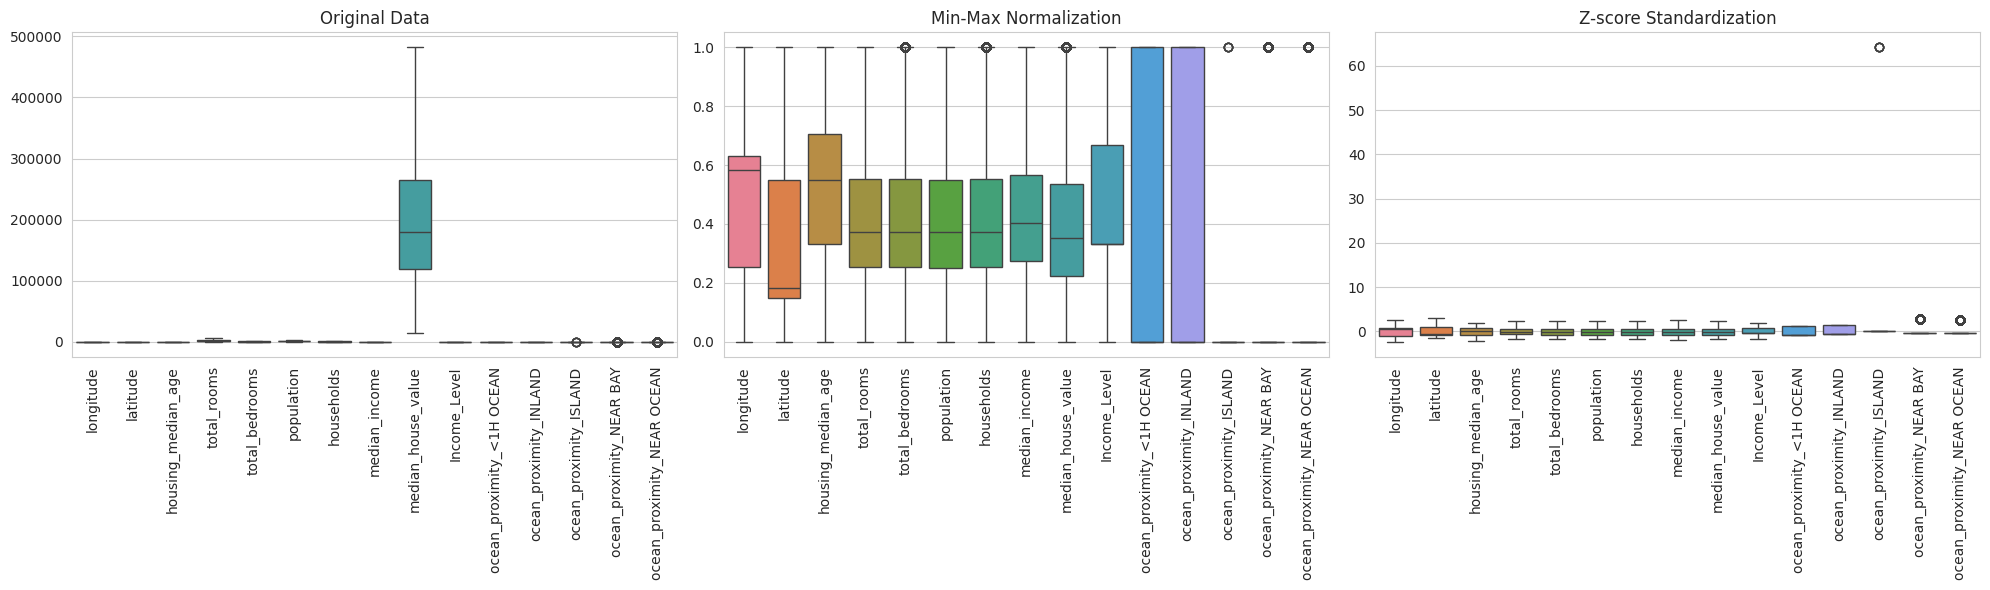

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(data=df[num_cols], ax=axes[0])
axes[0].set_title("Original Data")

sns.boxplot(data=df_minmax[num_cols], ax=axes[1])
axes[1].set_title("Min-Max Normalization")

sns.boxplot(data=df_standard[num_cols], ax=axes[2])
axes[2].set_title("Z-score Standardization")

for ax in axes:
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Original Mean": df[num_cols].mean(),
    "MinMax Mean": df_minmax[num_cols].mean(),
    "Zscore Mean": df_standard[num_cols].mean(),

    "Original Std": df[num_cols].std(),
    "MinMax Std": df_minmax[num_cols].std(),
    "Zscore Std": df_standard[num_cols].std()
})

print(comparison.round(3))

                            Original Mean  MinMax Mean  Zscore Mean  \
longitude                        -119.570        0.476         -0.0   
latitude                           35.632        0.329          0.0   
housing_median_age                 28.639        0.542          0.0   
total_rooms                      2441.692        0.428         -0.0   
total_bedrooms                    501.182        0.431          0.0   
population                       1336.959        0.426          0.0   
households                        469.020        0.429         -0.0   
median_income                       3.801        0.439         -0.0   
median_house_value             205981.225        0.409         -0.0   
Income_Level                        2.387        0.462         -0.0   
ocean_proximity_<1H OCEAN           0.443        0.443          0.0   
ocean_proximity_INLAND              0.317        0.317         -0.0   
ocean_proximity_ISLAND              0.000        0.000         -0.0   
ocean_

In [ ]:
df.to_csv("housing_cleaned.csv", index=False)

df_minmax.to_csv(
    "housing_minmax_normalized.csv",
    index=False
)

df_standard.to_csv(
    "housing_zscore_standardized.csv",
    index=False
)

print("All files saved successfully!")

All files saved successfully!
